# Lecture 10 · ARIMA Models and Exponential Smoothing

Following `10-3 ARIMA models.pdf` (Montgomery, Jennings & Kulahci, 2008, Ch. 5) and `10-4 Exponential smoothing methods.pdf` (Ch. 4). `10-1` and `10-2` are the week-9 lectures renamed and add nothing new.

**Data:** `AirPassengers.csv`, the monthly airline passengers of week 9 (Jan 1949 – Dec 1960, $T=144$). Models are built on $\ln y_t$ (variance-stabilizing, week 9) using the first $120$ months (1949–1958); the last $24$ months (1959–1960) are held out. Week 9 gave the benchmark: trend + season + AR(1) reached a one-step MAPE of $3.56\%$ on the same $24$ months.

**Sign convention.** The lecture writes $\theta(B)=1+\theta_1B+\dots$ ($y_t=\varepsilon_t+\theta_1\varepsilon_{t-1}$); `statsmodels` uses the same plus sign (checked below), so MA coefficients can be compared directly.

In [1]:
import numpy as np, pandas as pd, warnings
from scipy import stats, optimize
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima_process import arma_generate_sample, arma2ma
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings('ignore')
df = pd.read_csv('AirPassengers.csv', parse_dates=['date'])
y = df.set_index('date')['value'].astype(float)
yv = y.to_numpy(); ly = np.log(yv); T = len(yv); NTR = 120
month = y.index.month.to_numpy()
ltr = ly[:NTR]
assert (y.index.to_series().diff().dropna().dt.days.between(28, 31)).all() and not y.isna().any()
print(f'T = {T}, training months 1-{NTR} ({y.index[0]:%Y-%m} to {y.index[NTR-1]:%Y-%m}), hold-out {T-NTR} months ({y.index[NTR]:%Y-%m} to {y.index[-1]:%Y-%m})')

def sample_acf(x, K):
    x = np.asarray(x, float); m = len(x); xb = x.mean()
    c = np.array([((x[:m - k] - xb) * (x[k:] - xb)).sum() / m for k in range(K + 1)]); return c / c[0]
def nth_diff(x, d=1, lag=1):
    out = np.asarray(x, float)
    for _ in range(d): out = out[lag:] - out[:-lag]
    return out
def accuracy(actual, fc):
    e = actual - fc
    return dict(ME=e.mean(), MAD=np.abs(e).mean(), MSE=(e**2).mean(), RMSE=np.sqrt((e**2).mean()), MAPE=100 * np.mean(np.abs(e) / actual))

T = 144, training months 1-120 (1949-01 to 1958-12), hold-out 24 months (1959-01 to 1960-12)


# Part 1 · ARIMA models (10-3)

AR$(p)$: $y_t=\phi_1y_{t-1}+\dots+\phi_py_{t-p}+\varepsilon_t$; MA$(q)$: $y_t=\varepsilon_t+\theta_1\varepsilon_{t-1}+\dots$; ARMA mixes both. With the backshift operator
$$\phi(B)(1-B)^dy_t=\delta+\theta(B)\varepsilon_t,\qquad\phi(B)=1-\phi_1B-\dots-\phi_pB^p,\ \ \theta(B)=1+\theta_1B+\dots+\theta_qB^q$$
(slide 10); SARIMA$(p,d,q)(P,D,Q)_s$ adds the same terms at lag $s$ (slides 11–12).

## ACF versus PACF and identification (slides 5–8)

ACF $\rho_k=Corr(y_t,y_{t-k})$ is the total correlation; PACF $\phi_{kk}$ is the direct correlation after removing lags $1,\dots,k-1$ — the last coefficient of the regression of $y_t$ on $y_{t-1},\dots,y_{t-k}$.

AR(1), phi = 0.7:   rho_k = phi^k = [0.7  0.49 0.34 0.24]   (slide: 0.70, 0.49, 0.34, 0.24)
MA(1), theta = 0.5: rho_1 = theta/(1+theta^2) = 0.40, rho_k = 0 for k >= 2   (slide: 0.40)

PACF as the last regression coefficient equals statsmodels (method = ols): [ 0.516 -0.011  0.128 -0.022 -0.038 -0.06 ]
MA(1) simulated with theta = +0.5 is estimated by statsmodels as +0.503: same sign convention as the lecture



bound 2/sqrt(300) = 0.115; lags beyond the bound among the first 12:
  AR(1), phi = 0.7     ACF lags: [1, 2, 3, 4, 5, 6, 7, 8, 11, 12]   PACF lags: [1, 11]
  MA(1), theta = 0.5   ACF lags: [1, 11]   PACF lags: [1, 2, 10]


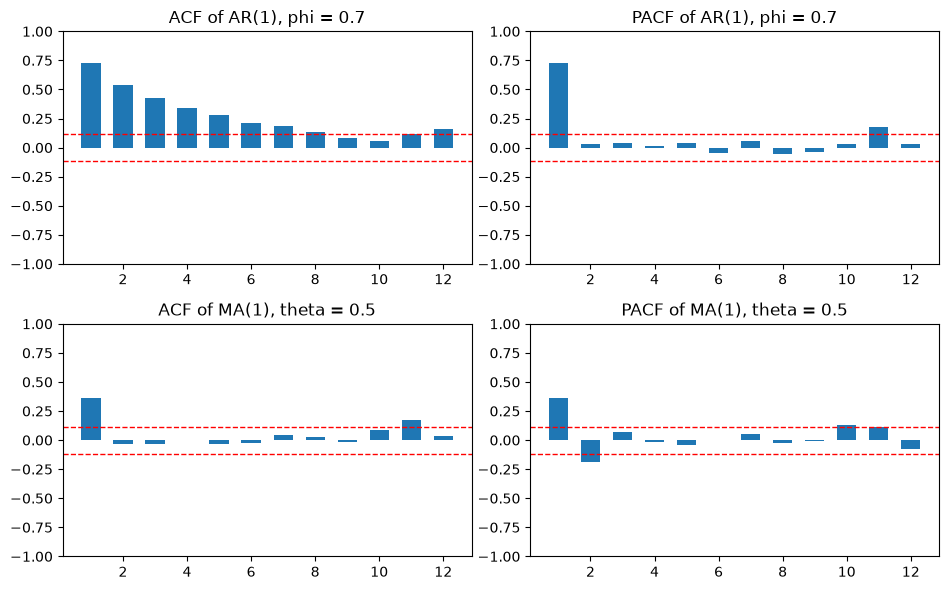

In [2]:
# worked example, slide 6
phi_, theta_ = 0.7, 0.5
print('AR(1), phi = 0.7:   rho_k = phi^k =', np.round(phi_ ** np.arange(1, 5), 2), '  (slide: 0.70, 0.49, 0.34, 0.24)')
print(f'MA(1), theta = 0.5: rho_1 = theta/(1+theta^2) = {theta_/(1+theta_**2):.2f}, rho_k = 0 for k >= 2   (slide: 0.40)\n')

# the PACF as the last coefficient of a regression: manual versus statsmodels
rng = np.random.default_rng(1)
x_ar = arma_generate_sample(ar=[1, -0.7], ma=[1], nsample=300, distrvs=lambda size: rng.standard_normal(size))
def pacf_manual(x, K):
    out = [1.0]
    for k in range(1, K + 1):
        Xr = np.column_stack([np.ones(len(x) - k)] + [x[k - j: len(x) - j] for j in range(1, k + 1)])
        b = np.linalg.lstsq(Xr, x[k:], rcond=None)[0]; out.append(b[-1])
    return np.array(out)
pm, ps = pacf_manual(x_ar, 6), pacf(x_ar, nlags=6, method='ols')
assert np.allclose(pm, ps, atol=1e-8), 'regression PACF differs from statsmodels (ols)'
print('PACF as the last regression coefficient equals statsmodels (method = ols):', np.round(pm[1:], 3))

# sign convention: MA(1) with theta = +0.5 is estimated as +0.5 by statsmodels
x_ma = arma_generate_sample(ar=[1], ma=[1, 0.5], nsample=3000, distrvs=lambda size: rng.standard_normal(size))
th = SARIMAX(x_ma, order=(0, 0, 1), trend='n').fit(disp=False).params[0]
print(f'MA(1) simulated with theta = +0.5 is estimated by statsmodels as {th:+.3f}: same sign convention as the lecture')

# identification signatures on simulated series (slide 7-8)
n_s = 300; xs = {'AR(1), phi = 0.7': arma_generate_sample(ar=[1, -0.7], ma=[1], nsample=n_s, distrvs=lambda size: rng.standard_normal(size)),
                 'MA(1), theta = 0.5': arma_generate_sample(ar=[1], ma=[1, 0.5], nsample=n_s, distrvs=lambda size: rng.standard_normal(size))}
bd_s = 2 / np.sqrt(n_s); K_s = 12
fig, ax = plt.subplots(2, 2, figsize=(9.5, 6))
print(f'\nbound 2/sqrt({n_s}) = {bd_s:.3f}; lags beyond the bound among the first {K_s}:')
for i, (nm_, x_) in enumerate(xs.items()):
    a_, p_ = acf(x_, nlags=K_s, fft=False), pacf(x_, nlags=K_s, method='ols')
    for j, (v_, lab) in enumerate([(a_, 'ACF'), (p_, 'PACF')]):
        ax[i, j].bar(range(1, K_s + 1), v_[1:], width=.6); ax[i, j].axhline(bd_s, c='r', ls='--', lw=1); ax[i, j].axhline(-bd_s, c='r', ls='--', lw=1)
        ax[i, j].set_title(f'{lab} of {nm_}'); ax[i, j].set_ylim(-1, 1)
    print(f'  {nm_:<20} ACF lags: {[k for k in range(1, K_s + 1) if abs(a_[k]) > bd_s]}   PACF lags: {[k for k in range(1, K_s + 1) if abs(p_[k]) > bd_s]}')
plt.tight_layout()
plt.savefig('images/acf_pacf_sim.png')
plt.show()

## Forecasting an AR(1) (slides 15–16)

$\hat y_{t+h}=\mu+\phi^h(y_t-\mu)$; with $\psi_j=\phi^j$ the error s.d. is $\sigma\sqrt{\sum_{j<h}\psi_j^2}=\sigma\sqrt{(1-\phi^{2h})/(1-\phi^2)}$ and the $95\%$ interval is $\hat y_{t+h}\pm1.96\,\sigma\sqrt{\sum\psi_j^2}$: it widens with $h$ but toward a fixed limit for a stationary model.

In [3]:
phi, mu, yt, sig = 0.7, 50.0, 58.0, 2.0
print(f'{"h":>4}{"forecast":>10}{"error sd":>10}{"95% interval":>20}')
for h_ in (1, 2, 3, 10 ** 6):
    f_ = mu + phi ** h_ * (yt - mu); s_ = sig * np.sqrt((1 - phi ** (2 * h_)) / (1 - phi ** 2))
    psi = phi ** np.arange(h_ if h_ < 50 else 200)
    if h_ < 50: assert np.isclose(s_, sig * np.sqrt((psi**2).sum()))
    print(f'{("inf" if h_ > 50 else h_):>4}{f_:>10.1f}{s_:>10.2f}   ({f_ - 1.96*s_:.1f}, {f_ + 1.96*s_:.1f})')
print('slide 16: 55.6 / 2.00 / (51.7, 59.5);  53.9 / 2.44 / (49.1, 58.7);  52.7 / 2.63 / (47.5, 57.9);  50.0 / 2.80 / 50.0 +- 5.5')

   h  forecast  error sd        95% interval
   1      55.6      2.00   (51.7, 59.5)
   2      53.9      2.44   (49.1, 58.7)
   3      52.7      2.63   (47.6, 57.9)
 inf      50.0      2.80   (44.5, 55.5)
slide 16: 55.6 / 2.00 / (51.7, 59.5);  53.9 / 2.44 / (49.1, 58.7);  52.7 / 2.63 / (47.5, 57.9);  50.0 / 2.80 / 50.0 +- 5.5


## Step 1 of Box–Jenkins: identification (slides 9 and 13)

A slowly decaying ACF means difference first. For the airline series: take logs, then the regular difference $(1-B)$ and the seasonal difference $(1-B^{12})$ (week 9). The ACF and PACF of $w_t=(1-B)(1-B^{12})\ln y_t$ on the training months suggest the orders; bound $\pm2/\sqrt{T}$, lags up to $K\approx T/4$.

w_t = (1-B)(1-B^12) ln y_t on the training months: n = 107, K = 26, bound = 0.193
ACF  lags beyond the bound: [(1, np.float64(-0.33)), (3, np.float64(-0.22)), (12, np.float64(-0.41)), (23, np.float64(0.23))]
PACF lags beyond the bound: [(1, np.float64(-0.33)), (3, np.float64(-0.21)), (12, np.float64(-0.37)), (23, np.float64(0.2))]

reading: the ACF spikes at lag 1 and at the seasonal lag 12 point towards MA(1) x seasonal MA(1)_12 (the airline model); the PACF is significant at the same lags, so there is no clean cut-off and AR alternatives are fitted too.


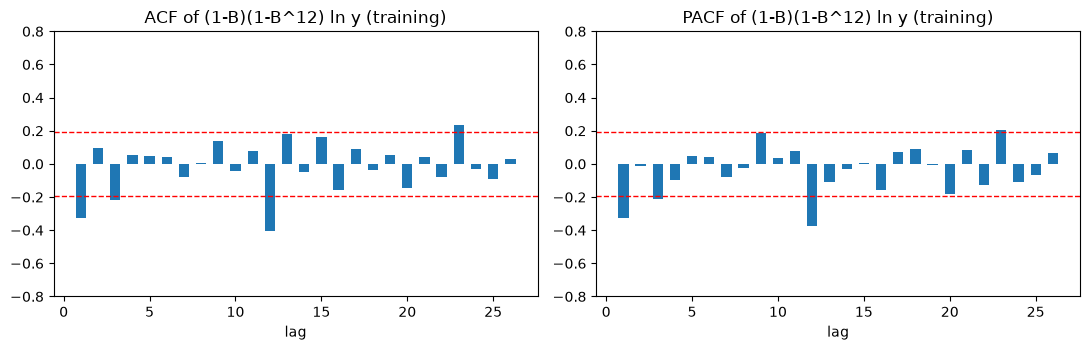

In [4]:
w_tr = nth_diff(nth_diff(ltr, 1, 12), 1, 1)
Kw = len(w_tr) // 4; bw = 2 / np.sqrt(len(w_tr))
aw, pw = acf(w_tr, nlags=Kw, fft=False), pacf(w_tr, nlags=Kw, method='ols')
print(f'w_t = (1-B)(1-B^12) ln y_t on the training months: n = {len(w_tr)}, K = {Kw}, bound = {bw:.3f}')
print('ACF  lags beyond the bound:', [(k, round(aw[k], 2)) for k in range(1, Kw + 1) if abs(aw[k]) > bw])
print('PACF lags beyond the bound:', [(k, round(pw[k], 2)) for k in range(1, Kw + 1) if abs(pw[k]) > bw])
print('\nreading: the ACF spikes at lag 1 and at the seasonal lag 12 point towards MA(1) x seasonal MA(1)_12 (the airline model); the PACF is significant at the same lags, so there is no clean cut-off and AR alternatives are fitted too.')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, v_, lab in [(ax[0], aw, 'ACF'), (ax[1], pw, 'PACF')]:
    a.bar(range(1, Kw + 1), v_[1:], width=.6); a.axhline(bw, c='r', ls='--', lw=1); a.axhline(-bw, c='r', ls='--', lw=1)
    a.set_title(f'{lab} of (1-B)(1-B^12) ln y (training)'); a.set_xlabel('lag'); a.set_ylim(-.8, .8)
plt.tight_layout()
plt.savefig('images/acf_pacf_airline.png')
plt.show()

## Steps 2 and 3: estimation, diagnostics and comparison (slides 13–14)

Candidates on $\ln y_t$, all with $d=D=1$ so that their information criteria are comparable, fitted by maximum likelihood. Diagnostics: the residuals must look like white noise — Ljung–Box with $K\approx T/4$ and $K-k$ degrees of freedom, $k$ the number of fitted ARMA coefficients ($\sigma^2$ excluded).
AIC and BIC are the software's (they count $\sigma^2$ among the parameters and are not divided by $T$); only differences matter. The lecture's table on slide 14 is marked illustrative and is not used.

In [5]:
cands = {'(0,1,1)(0,1,1)12': ((0, 1, 1), (0, 1, 1, 12)),
         '(1,1,0)(0,1,1)12': ((1, 1, 0), (0, 1, 1, 12)),
         '(0,1,1)(1,1,0)12': ((0, 1, 1), (1, 1, 0, 12)),
         '(1,1,1)(0,1,1)12': ((1, 1, 1), (0, 1, 1, 12)),
         '(0,1,2)(0,1,1)12': ((0, 1, 2), (0, 1, 1, 12)),
         '(2,1,0)(0,1,1)12': ((2, 1, 0), (0, 1, 1, 12))}
fits = {nm_: SARIMAX(ltr, order=o_, seasonal_order=s_, trend='n').fit(disp=False, maxiter=300) for nm_, (o_, s_) in cands.items()}
burn = 13                                         # d + D*s observations are lost to differencing
rows = []
for nm_, r_ in fits.items():
    k_ = len(r_.params) - 1                       # ARMA coefficients, sigma2 excluded
    e_ = r_.resid[burn:]; Te = len(e_); Ke = Te // 4
    rr = sample_acf(e_, Ke); Q = Te * (Te + 2) * (rr[1:]**2 / (Te - np.arange(1, Ke + 1))).sum()
    lb = acorr_ljungbox(e_, lags=[Ke], model_df=k_)
    assert np.isclose(lb['lb_stat'].iloc[0], Q), 'Ljung-Box differs from statsmodels'
    rows.append(dict(model=nm_, k=k_, AIC=r_.aic, BIC=r_.bic, sigma=np.sqrt(r_.params[-1]), K=Ke, LB=Q, p=stats.chi2.sf(Q, Ke - k_)))
tab = pd.DataFrame(rows)
tab['dAIC'] = tab['AIC'] - tab['AIC'].min(); tab['dBIC'] = tab['BIC'] - tab['BIC'].min()
print(tab[['model', 'k', 'AIC', 'dAIC', 'BIC', 'dBIC', 'sigma', 'K', 'LB', 'p']].to_string(index=False, float_format=lambda v: f'{v:.4f}'))
best_nm = tab.loc[tab['BIC'].idxmin(), 'model']; print(f'\nminimum AIC: {tab.loc[tab.AIC.idxmin(), "model"]};  minimum BIC: {best_nm}')
r_best = fits[best_nm]
print(f'\n{best_nm}: coefficients')
print(pd.DataFrame({'estimate': r_best.params, 'se': r_best.bse, 'z': r_best.params / r_best.bse}, index=r_best.param_names).round(4).to_string())

           model  k       AIC   dAIC       BIC   dBIC  sigma  K      LB      p
(0,1,1)(0,1,1)12  2 -389.0097 0.0000 -380.9913 0.0000 0.0375 26 18.4411 0.7811
(1,1,0)(0,1,1)12  2 -388.6431 0.3666 -380.6247 0.3666 0.0375 26 21.0378 0.6365
(0,1,1)(1,1,0)12  2 -384.2315 4.7782 -376.2130 4.7782 0.0385 26 23.9085 0.4668
(1,1,1)(0,1,1)12  3 -387.2791 1.7307 -376.5877 4.4035 0.0374 26 17.2984 0.7944
(0,1,2)(0,1,1)12  3 -387.0654 1.9443 -376.3741 4.6172 0.0374 26 17.9831 0.7584
(2,1,0)(0,1,1)12  3 -386.6578 2.3520 -375.9664 5.0248 0.0375 26 20.8398 0.5909

minimum AIC: (0,1,1)(0,1,1)12;  minimum BIC: (0,1,1)(0,1,1)12

(0,1,1)(0,1,1)12: coefficients
          estimate      se       z
ma.L1      -0.3420  0.0873 -3.9176
ma.S.L12   -0.5404  0.1048 -5.1541
sigma2      0.0014  0.0002  7.8640


A non-seasonal ARIMA(1,1,1) on $\ln y$ shows why the seasonal terms matter: its residuals keep the seasonal pattern. (It has $D=0$, so its AIC is not comparable with the table above and only the diagnostics are shown.)

ARIMA(1,1,1) on ln y, no seasonal difference: residual ACF at lag 12 = +0.743 (bound 0.183), lags beyond the bound: 7 of 29;  Ljung-Box = 201.8, P = 1.1e-28
(0,1,1)(0,1,1)12: residual lags beyond the bound: [23] of 26;  normal probability plot r = 0.9928


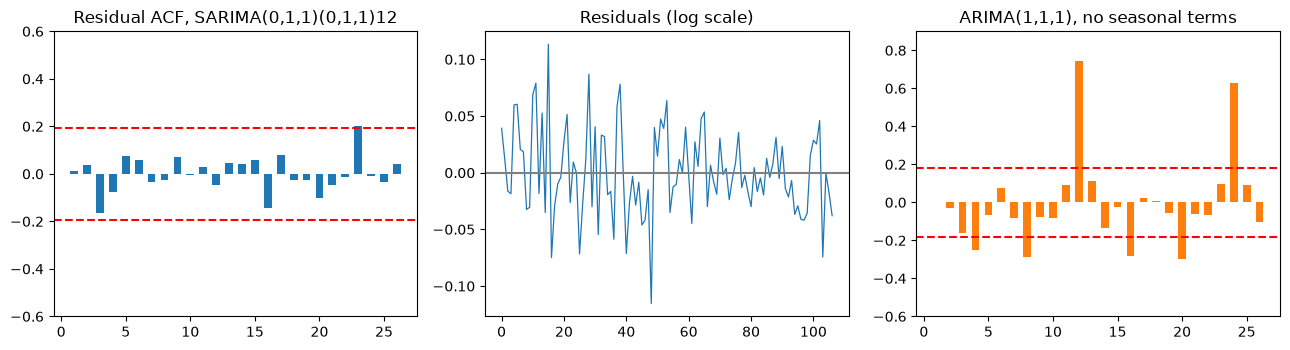

In [6]:
r_ns = SARIMAX(ltr, order=(1, 1, 1), trend='n').fit(disp=False)
e_ns = r_ns.resid[1:]; Te = len(e_ns); Ke = Te // 4; rr = sample_acf(e_ns, Ke)
Q = Te * (Te + 2) * (rr[1:]**2 / (Te - np.arange(1, Ke + 1))).sum()
print(f'ARIMA(1,1,1) on ln y, no seasonal difference: residual ACF at lag 12 = {rr[12]:+.3f} (bound {2/np.sqrt(Te):.3f}), lags beyond the bound: {int((np.abs(rr[1:]) > 2/np.sqrt(Te)).sum())} of {Ke};  Ljung-Box = {Q:.1f}, P = {stats.chi2.sf(Q, Ke - 2):.2g}')

e_b = r_best.resid[burn:]; Te = len(e_b); Ke = Te // 4; rr_b = sample_acf(e_b, Ke); bd_b = 2 / np.sqrt(Te)
print(f'{best_nm}: residual lags beyond the bound: {[k for k in range(1, Ke + 1) if abs(rr_b[k]) > bd_b]} of {Ke};  normal probability plot r = '
      f'{np.corrcoef(np.sort(e_b), stats.norm.ppf((np.arange(1, Te + 1) - .375) / (Te + .25)))[0, 1]:.4f}')

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].bar(range(1, Ke + 1), rr_b[1:], width=.6); ax[0].axhline(bd_b, c='r', ls='--'); ax[0].axhline(-bd_b, c='r', ls='--'); ax[0].set_title(f'Residual ACF, SARIMA{best_nm}'); ax[0].set_ylim(-.6, .6)
ax[1].plot(e_b, lw=.9); ax[1].axhline(0, c='gray'); ax[1].set_title('Residuals (log scale)')
rr_ns = sample_acf(e_ns, Ke); bn_ = 2 / np.sqrt(len(e_ns))
ax[2].bar(range(1, Ke + 1), rr_ns[1:], width=.6, color='C1'); ax[2].axhline(bn_, c='r', ls='--'); ax[2].axhline(-bn_, c='r', ls='--'); ax[2].set_title('ARIMA(1,1,1), no seasonal terms'); ax[2].set_ylim(-.6, .9)
plt.tight_layout()
plt.savefig('images/arima_residuals.png')
plt.show()

## Forecasts and prediction intervals (slide 15)

$\hat y_{t+h}$ is the conditional expectation (future errors replaced by $0$); with $y_t=\sum_{j\ge0}\psi_j\varepsilon_{t-j}$ the error variance is $\sigma^2\sum_{j<h}\psi_j^2$ and the interval widens with $h$.
For SARIMA the $\psi_j$ come from the full operator $\phi(B)\Phi(B^{s})(1-B)^d(1-B^{s})^D$ (the AR side) and $\theta(B)\Theta(B^s)$ (the MA side). They are computed here and compared with the software's standard errors. Forecasts are made on the log scale and back-transformed with $\exp$.

psi weights (first 6): [1.    0.658 0.658 0.658 0.658 0.658]
forecast standard error on the log scale, formula vs. software: h = 1: 0.0375 / 0.0375;  h = 12: 0.0899 / 0.0899;  h = 24: 0.1551 / 0.1551
largest relative difference over h = 1..24: 0.001%

24-step forecasts from the end of 1958 (origin T = 120), original scale:  MAD 39.5, RMSE 43.2, MAPE 8.52%
actual values inside the 95% interval: 24 of 24;  interval width at h = 1: 51, h = 12: 129, h = 24: 240


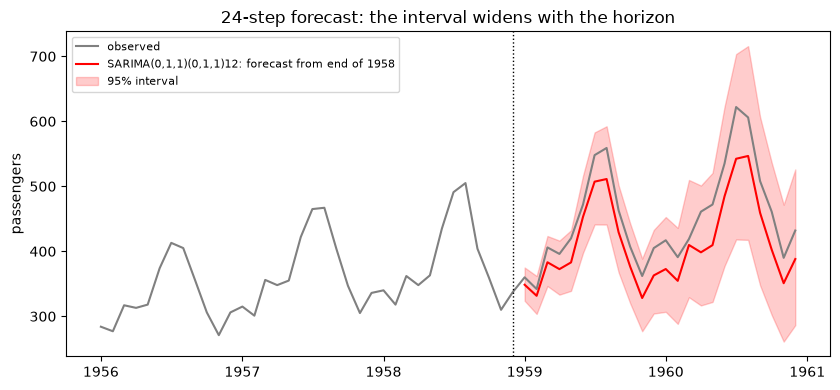

In [7]:
def full_polys(res, order, sorder):
    p_, d_, q_ = order; P_, D_, Q_, s_ = sorder; pr = dict(zip(res.param_names, res.params))
    ar = np.r_[1, -np.array([pr[f'ar.L{i}'] for i in range(1, p_ + 1)])] if p_ else np.array([1.0])
    ma = np.r_[1, np.array([pr[f'ma.L{i}'] for i in range(1, q_ + 1)])] if q_ else np.array([1.0])
    def seas(c, n_, sign):
        out = np.zeros(n_ * s_ + 1); out[0] = 1
        for i in range(1, n_ + 1): out[i * s_] = sign * c[i - 1]
        return out
    SAR = seas([pr[f'ar.S.L{i * s_}'] for i in range(1, P_ + 1)], P_, -1) if P_ else np.array([1.0])
    SMA = seas([pr[f'ma.S.L{i * s_}'] for i in range(1, Q_ + 1)], Q_, +1) if Q_ else np.array([1.0])
    arf = np.polymul(ar, SAR); maf = np.polymul(ma, SMA)
    for _ in range(d_): arf = np.polymul(arf, [1, -1])
    dd = np.zeros(s_ + 1); dd[0], dd[-1] = 1, -1
    for _ in range(D_): arf = np.polymul(arf, dd)
    return arf, maf

H = T - NTR
o_b, s_b = cands[best_nm]
arf, maf = full_polys(r_best, o_b, s_b)
psi = arma2ma(arf, maf, H)
sigma2 = r_best.params[-1]
se_psi = np.sqrt(sigma2 * np.cumsum(psi**2))
fc = r_best.get_forecast(H); sf = fc.summary_frame(alpha=0.05)
print(f'psi weights (first 6): {np.round(psi[:6], 3)}')
print(f'forecast standard error on the log scale, formula vs. software: h = 1: {se_psi[0]:.4f} / {fc.se_mean[0]:.4f};  h = 12: {se_psi[11]:.4f} / {fc.se_mean[11]:.4f};  h = 24: {se_psi[23]:.4f} / {fc.se_mean[23]:.4f}')
print(f'largest relative difference over h = 1..{H}: {np.max(np.abs(se_psi / fc.se_mean - 1)):.3%}')

lo, up = np.exp(sf['mean_ci_lower'].to_numpy()), np.exp(sf['mean_ci_upper'].to_numpy()); pt = np.exp(sf['mean'].to_numpy())
act = yv[NTR:]
a_ = accuracy(act, pt)
print(f'\n{H}-step forecasts from the end of 1958 (origin T = {NTR}), original scale:  MAD {a_["MAD"]:.1f}, RMSE {a_["RMSE"]:.1f}, MAPE {a_["MAPE"]:.2f}%')
print(f'actual values inside the 95% interval: {int(((act >= lo) & (act <= up)).sum())} of {H};  interval width at h = 1: {up[0]-lo[0]:.0f}, h = 12: {up[11]-lo[11]:.0f}, h = 24: {up[-1]-lo[-1]:.0f}')

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(y.index[-60:], yv[-60:], color='gray', label='observed')
ax.plot(y.index[NTR:], pt, 'r-', label=f'SARIMA{best_nm}: forecast from end of 1958')
ax.fill_between(y.index[NTR:], lo, up, alpha=.2, color='r', label='95% interval')
ax.axvline(y.index[NTR - 1], c='k', ls=':', lw=1); ax.set_ylabel('passengers'); ax.legend(fontsize=8, loc='upper left'); ax.set_title('24-step forecast: the interval widens with the horizon')
plt.tight_layout()
plt.savefig('images/arima_forecast.png')
plt.show()

# Part 2 · Exponential smoothing (10-4)

**Simple (first order):** $\tilde y_t=\lambda y_t+(1-\lambda)\tilde y_{t-1}$, one-step forecast $F_t=\tilde y_{t-1}$, weights $\lambda(1-\lambda)^k$ on the past.
**Holt:** $L_t=\alpha y_t+(1-\alpha)(L_{t-1}+T_{t-1})$, $T_t=\beta(L_t-L_{t-1})+(1-\beta)T_{t-1}$, $\hat y_{t+\tau}=L_t+\tau T_t$.
**Holt–Winters** adds a seasonal factor $S_t$ with constant $\gamma$ (additive: $\hat y_{t+\tau}=L_t+\tau T_t+S_{t+\tau-s}$; multiplicative: $(L_t+\tau T_t)S_{t+\tau-s}$), updates as on slide 11.
The smoothing constants minimise the one-step squared error; initial values come from the first season(s) (slide 14).

## The worked examples (slides 5 and 9)

In [8]:
def ses_run(yy, lam):
    sm_ = [yy[0]]; F = [np.nan]
    for t in range(1, len(yy)):
        F.append(sm_[-1]); sm_.append(lam * yy[t] + (1 - lam) * sm_[-1])
    return np.array(sm_), np.array(F)

d7 = np.array([120, 135, 125, 140, 150, 145, 160.])
s7, F7 = ses_run(d7, 0.3)
print('simple smoothing, lambda = 0.3, y~1 = 120   (slide 5):')
print(f'{"t":>3}{"y":>6}{"forecast":>10}{"error":>8}{"smoothed":>10}')
for t in range(7): print(f'{t+1:>3}{d7[t]:>6.0f}{("" if t == 0 else f"{F7[t]:.2f}"):>10}{("" if t == 0 else f"{d7[t]-F7[t]:+.2f}"):>8}{s7[t]:>10.2f}')
print(f'forecast for t = 8: {s7[-1]:.2f}  (unrounded {s7[-1]:.3f}). The slide rounds every step to two decimals, so it shows 129.26 and 138.34 where the unrounded values are {s7[3]:.3f} and {s7[5]:.3f}.')
assert np.allclose(np.round(s7, 2), [120, 124.5, 124.65, 129.26, 135.48, 138.34, 144.83], atol=0.011)

def holt_run(yy, a, b, L1=None, T1=None):
    L = [yy[0] if L1 is None else L1]; Tr = [yy[1] - yy[0] if T1 is None else T1]; F = [np.nan]
    for t in range(1, len(yy)):
        F.append(L[-1] + Tr[-1]); Lt = a * yy[t] + (1 - a) * (L[-1] + Tr[-1]); Tr.append(b * (Lt - L[-1]) + (1 - b) * Tr[-1]); L.append(Lt)
    return np.array(L), np.array(Tr), np.array(F)
Lh, Th, Fh = holt_run(np.array([50, 53, 56, 58.]), 0.3, 0.2)
print(f'\nHolt, alpha = 0.3, beta = 0.2, y = 50, 53, 56, 58   (slide 9):  L = {np.round(Lh, 2)},  T = {np.round(Th, 2)},  1-step forecasts {np.round(Fh[1:], 2)}')
print(f'forecasts from t = 4: tau = 1: {Lh[-1] + Th[-1]:.2f},  tau = 2: {Lh[-1] + 2*Th[-1]:.2f}   (slide: 61.64, 64.58)')
assert np.allclose([Lh[-1], Th[-1], Lh[-1] + Th[-1], Lh[-1] + 2 * Th[-1]], [58.70, 2.94, 61.64, 64.58], atol=0.011)

simple smoothing, lambda = 0.3, y~1 = 120   (slide 5):
  t     y  forecast   error  smoothed
  1   120                      120.00
  2   135    120.00  +15.00    124.50
  3   125    124.50   +0.50    124.65
  4   140    124.65  +15.35    129.25
  5   150    129.25  +20.75    135.48
  6   145    135.48   +9.52    138.33
  7   160    138.33  +21.67    144.83
forecast for t = 8: 144.83  (unrounded 144.834). The slide rounds every step to two decimals, so it shows 129.26 and 138.34 where the unrounded values are 129.255 and 138.335.

Holt, alpha = 0.3, beta = 0.2, y = 50, 53, 56, 58   (slide 9):  L = [50.  53.  56.  58.7],  T = [3.   3.   3.   2.94],  1-step forecasts [53. 56. 59.]
forecasts from t = 4: tau = 1: 61.64,  tau = 2: 64.58   (slide: 61.64, 64.58)


## Smoothing the airline series

Fitted on the training months ($t\le120$): simple smoothing, Holt, additive Holt–Winters and multiplicative Holt–Winters on the original scale, and additive Holt–Winters on $\ln y$. The constants minimise the sum of squared one-step errors; initial values (level, trend and seasonal factors) are least-squares estimates from the first $24$ months (two seasons), and the recursion starts at $t=12$.

In [9]:
S_ = 12
def init_hw(yy, mult):
    n2 = 2 * S_; tt = np.arange(1, n2 + 1)
    base = np.polyfit(tt, yy[:n2], 1)                       # trend over the first two seasons
    tr = np.polyval(base, tt)
    if mult:
        ratio = yy[:n2] / tr; seas = np.array([ratio[m::S_].mean() for m in range(S_)]); seas = seas / seas.mean()
    else:
        dev = yy[:n2] - tr; seas = np.array([dev[m::S_].mean() for m in range(S_)]); seas = seas - seas.mean()
    return np.polyval(base, S_), base[0], seas                # level and trend at t = s, seasonal factors for positions 1..s

def hw_run(yy, a, b, g, mult, init, horizon=0, form='lecture'):
    L0, T0, seas = init; L, Tr = [L0], [T0]; S = list(seas); F = {}
    for t in range(S_, len(yy)):                            # 0-based index t; yy[t] forecast from state at t-1
        St = S[t - S_] if t - S_ < len(S) else None
        f = (L[-1] + Tr[-1]) * St if mult else L[-1] + Tr[-1] + St
        F[t] = f
        Lt = a * (yy[t] / St if mult else yy[t] - St) + (1 - a) * (L[-1] + Tr[-1])
        Tt = b * (Lt - L[-1]) + (1 - b) * Tr[-1]
        if form == 'statsmodels' and mult: Sn = g * (yy[t] / (L[-1] + Tr[-1])) + (1 - g) * St      # previous level, as statsmodels
        else: Sn = g * (yy[t] / Lt if mult else yy[t] - Lt) + (1 - g) * St
        L.append(Lt); Tr.append(Tt); S.append(Sn)
    out = dict(L=np.array(L), T=np.array(Tr), S=np.array(S), F=F)
    if horizon:
        n = len(yy); Lh_, Th_ = L[-1], Tr[-1]
        out['fc'] = np.array([(Lh_ + tau * Th_) * S[n - S_ + (tau - 1) % S_ + (0)] if mult else Lh_ + tau * Th_ + S[n - S_ + (tau - 1) % S_] for tau in range(1, horizon + 1)])
    return out

def sse_fun(params, yy, mult, init, kind):
    if kind == 'hw': a, b, g = params; r = hw_run(yy, a, b, g, mult, init)
    f = np.array([r['F'][t] for t in range(S_, len(yy))]); return ((yy[S_:] - f)**2).sum()

def fit_hw(yy, mult):
    init = init_hw(yy, mult); best = None
    for x0 in ([.3, .1, .3], [.5, .05, .5], [.8, .2, .1]):
        r = optimize.minimize(sse_fun, x0, args=(yy, mult, init, 'hw'), bounds=[(1e-3, .999)] * 3, method='L-BFGS-B')
        if best is None or r.fun < best.fun: best = r
    return best.x, init, best.fun

ytr = yv[:NTR]
# simple smoothing and Holt on the original scale
lam_hat = optimize.minimize_scalar(lambda l: ((ytr[1:] - ses_run(ytr, l)[1][1:])**2).sum(), bounds=(1e-3, .999), method='bounded').x
hr = optimize.minimize(lambda p_: ((ytr[2:] - holt_run(ytr, p_[0], p_[1])[2][2:])**2).sum(), [.5, .1], bounds=[(1e-3, .999)] * 2, method='L-BFGS-B').x
(a_add, b_add, g_add), init_add, sse_add = fit_hw(ytr, False)
(a_mul, b_mul, g_mul), init_mul, sse_mul = fit_hw(ytr, True)
(a_lg, b_lg, g_lg), init_lg, sse_lg = fit_hw(ltr, False)
print(f'simple smoothing:             lambda = {lam_hat:.3f}')
print(f'Holt:                         alpha = {hr[0]:.3f}, beta = {hr[1]:.3f}')
print(f'Holt-Winters additive:        alpha = {a_add:.3f}, beta = {b_add:.3f}, gamma = {g_add:.3f}   (SSE of one-step errors {sse_add:,.0f})')
print(f'Holt-Winters multiplicative:  alpha = {a_mul:.3f}, beta = {b_mul:.3f}, gamma = {g_mul:.3f}   (SSE {sse_mul:,.0f})')
print(f'Holt-Winters additive on ln y: alpha = {a_lg:.3f}, beta = {b_lg:.3f}, gamma = {g_lg:.3f}   (SSE on the log scale {sse_lg:.4f})')
print(f'\ninitial seasonal factors (Jan..Dec), multiplicative: {np.round(init_mul[2], 3)}  (mean {init_mul[2].mean():.3f})')
print(f'initial seasonal factors, additive: {np.round(init_add[2], 1)}  (sum {init_add[2].sum():.1f})')

simple smoothing:             lambda = 0.999
Holt:                         alpha = 0.999, beta = 0.006
Holt-Winters additive:        alpha = 0.240, beta = 0.032, gamma = 0.999   (SSE of one-step errors 16,693)
Holt-Winters multiplicative:  alpha = 0.310, beta = 0.031, gamma = 0.999   (SSE 11,719)
Holt-Winters additive on ln y: alpha = 0.373, beta = 0.006, gamma = 0.838   (SSE on the log scale 0.1825)

initial seasonal factors (Jan..Dec), multiplicative: [0.889 0.948 1.052 1.011 0.935 1.07  1.188 1.18  1.083 0.922 0.792 0.93 ]  (mean 1.000)
initial seasonal factors, additive: [-14.3  -6.8   6.7   1.3  -8.7   9.3  25.3  24.4  11.4 -10.6 -28.5  -9.5]  (sum 0.0)


## Checking the recursions against `statsmodels`

`statsmodels` writes the seasonal update in error-correction form, $S_t=S_{t-s}+\gamma_{sm}\,e_t$ with $e_t$ the one-step error, while the lecture (slide 11) updates $S_t=\gamma(y_t-L_t)+(1-\gamma)S_{t-s}$ with the **new** level $L_t$.
Substituting $y_t-L_t=(1-\alpha)e_t$ shows $\gamma_{sm}=\gamma(1-\alpha)$ for the additive model; this is tested below with identical initial states. In the multiplicative model `statsmodels` divides by the previous level $L_{t-1}+T_{t-1}$ instead of $L_t$, so no mapping exists; the lecture's form is compared with it and with `statsmodels`' own form.

In [10]:
def check_sm(yy, a, b, g, init, mult, form='lecture', gamma_sm=None):
    L0, T0, seas = init; x = yy[S_:]
    mdl = ExponentialSmoothing(x, trend='add', seasonal='mul' if mult else 'add', seasonal_periods=S_, initialization_method='known',
                               initial_level=L0, initial_trend=T0, initial_seasonal=np.array(seas))
    r = mdl.fit(smoothing_level=a, smoothing_trend=b, smoothing_seasonal=gamma_sm, optimized=False)
    mine = hw_run(yy, a, b, g, mult, init, form=form)['F']; mine = np.array([mine[t] for t in range(S_, len(yy))])
    return np.abs(r.fittedvalues - mine).max(), np.abs(mine).max()
print('additive (lecture update, statsmodels gamma = gamma (1 - alpha)):')
dmax, scale = check_sm(ytr, a_add, b_add, g_add, init_add, False, gamma_sm=g_add * (1 - a_add))
print(f'   max |my one-step forecast - statsmodels| = {dmax:.2e}  (forecasts up to {scale:.0f})')
print('multiplicative:')
dmax, scale = check_sm(ytr, a_mul, b_mul, g_mul, init_mul, True, gamma_sm=g_mul * (1 - a_mul))
print(f'   lecture update (S_t from the new level L_t), gamma mapped as above: max difference = {dmax:.2f}  (forecasts up to {scale:.0f}); no exact mapping exists')
dmax2, _ = check_sm(ytr, a_mul, b_mul, g_mul, init_mul, True, form='statsmodels', gamma_sm=g_mul)
print(f'   statsmodels update (S_t from the previous level L_(t-1) + T_(t-1)), same constants: max difference = {dmax2:.2e}')
print('-> the recursions are correct; the multiplicative seasonal update of the lecture is a slightly different (new-level) form than the one in statsmodels, so the two give nearby but not identical forecasts.')


additive (lecture update, statsmodels gamma = gamma (1 - alpha)):
   max |my one-step forecast - statsmodels| = 1.14e-13  (forecasts up to 472)
multiplicative:
   lecture update (S_t from the new level L_t), gamma mapped as above: max difference = 0.80  (forecasts up to 478); no exact mapping exists
   statsmodels update (S_t from the previous level L_(t-1) + T_(t-1)), same constants: max difference = 1.14e-13
-> the recursions are correct; the multiplicative seasonal update of the lecture is a slightly different (new-level) form than the one in statsmodels, so the two give nearby but not identical forecasts.


## Hold-out comparison and the link to ARIMA (slide 14)

Forecasts of the last $24$ months from the end of 1958 ($\tau=1,\dots,24$), and one-step forecasts over the same months with the constants held fixed (the state keeps updating). Compared with week 9's trend + season + AR(1) (refitted each month, one-step MAPE $3.56\%$).

method                              24-step MAPE %  24-step RMSE  1-step MAPE %  1-step RMSE  1-step ME
simple smoothing                             23.58         137.4           9.73         51.8        4.0
Holt                                         14.52          97.4           9.65         51.8       -0.2
Holt-Winters additive                         6.69          35.8           2.68         15.0        4.2
Holt-Winters multiplicative                   7.30          36.8           2.59         14.9        2.9
Holt-Winters additive, ln y                   3.85          19.1           2.29         14.6        1.0
SARIMA(0,1,1)(0,1,1)12                        8.52          43.2           2.55         15.3        1.4

week 9, trend + season + AR(1) (refitted each month): one-step MAPE 3.56%, RMSE 19.6
simple smoothing lags the trend: 14 of 24 one-step errors are positive (the series is rising)


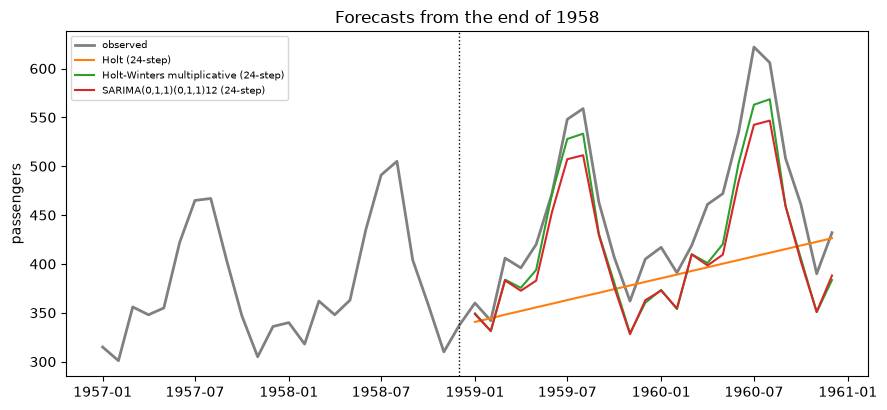

In [11]:
# multi-step forecasts from the origin T = 120
ses_fc = np.full(H, ses_run(ytr, lam_hat)[0][-1])
Lh_, Th_, _ = holt_run(ytr, hr[0], hr[1]); holt_fc = Lh_[-1] + np.arange(1, H + 1) * Th_[-1]
hw_a = hw_run(ytr, a_add, b_add, g_add, False, init_add, horizon=H)['fc']
hw_m = hw_run(ytr, a_mul, b_mul, g_mul, True, init_mul, horizon=H)['fc']
hw_l = np.exp(hw_run(ltr, a_lg, b_lg, g_lg, False, init_lg, horizon=H)['fc'])
arima_fc = pt
multi = {'simple smoothing': ses_fc, 'Holt': holt_fc, 'Holt-Winters additive': hw_a, 'Holt-Winters multiplicative': hw_m, 'Holt-Winters additive, ln y': hw_l, f'SARIMA{best_nm}': arima_fc}

# one-step forecasts over the hold-out with the constants fixed (the state keeps updating)
def one_step_holdout(kind):
    if kind == 'ses': F = ses_run(yv, lam_hat)[1]
    elif kind == 'holt': F = holt_run(yv, hr[0], hr[1])[2]
    elif kind == 'add': r = hw_run(yv, a_add, b_add, g_add, False, init_add); F = np.array([r['F'].get(t, np.nan) for t in range(T)])
    elif kind == 'mul': r = hw_run(yv, a_mul, b_mul, g_mul, True, init_mul); F = np.array([r['F'].get(t, np.nan) for t in range(T)])
    elif kind == 'log': r = hw_run(ly, a_lg, b_lg, g_lg, False, init_lg); F = np.exp(np.array([r['F'].get(t, np.nan) for t in range(T)]))
    return F[NTR:]
res_full = r_best.append(ly[NTR:], refit=False)
sarima_1 = np.exp(res_full.predict(start=NTR, end=T - 1))
one = {'simple smoothing': one_step_holdout('ses'), 'Holt': one_step_holdout('holt'), 'Holt-Winters additive': one_step_holdout('add'),
       'Holt-Winters multiplicative': one_step_holdout('mul'), 'Holt-Winters additive, ln y': one_step_holdout('log'), f'SARIMA{best_nm}': np.asarray(sarima_1)}
print(f'{"method":<34}{"24-step MAPE %":>16}{"24-step RMSE":>14}{"1-step MAPE %":>15}{"1-step RMSE":>13}{"1-step ME":>11}')
cmp_rows = {}
for nm_ in multi:
    am, ao = accuracy(act, multi[nm_]), accuracy(act, one[nm_]); cmp_rows[nm_] = (am, ao)
    print(f'{nm_:<34}{am["MAPE"]:>16.2f}{am["RMSE"]:>14.1f}{ao["MAPE"]:>15.2f}{ao["RMSE"]:>13.1f}{ao["ME"]:>11.1f}')
print('\nweek 9, trend + season + AR(1) (refitted each month): one-step MAPE 3.56%, RMSE 19.6')
print(f'simple smoothing lags the trend: {int(((act - one["simple smoothing"]) > 0).sum())} of {H} one-step errors are positive (the series is rising)')

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(y.index[-48:], yv[-48:], color='gray', lw=2, label='observed')
for nm_, c_ in [('Holt', 'C1'), ('Holt-Winters multiplicative', 'C2'), (f'SARIMA{best_nm}', 'C3')]:
    ax.plot(y.index[NTR:], multi[nm_], color=c_, label=f'{nm_} (24-step)')
ax.axvline(y.index[NTR - 1], c='k', ls=':', lw=1); ax.set_ylabel('passengers'); ax.legend(fontsize=7, loc='upper left'); ax.set_title('Forecasts from the end of 1958')
plt.tight_layout()
plt.savefig('images/forecast_comparison.png')
plt.show()

In [12]:
# equivalence: simple smoothing = ARIMA(0,1,1);  Holt = ARIMA(0,2,2)  (slide 14)
# Shown on two SYNTHETIC series where the smoothers are the right model, then on the airline series.
def one_step_arima(res, burn_, n): return np.asarray(res.predict(start=burn_, end=n - 1))
rng2 = np.random.default_rng(3); n2 = 500; k0 = 20
# (a) local level: y_t = level_t + noise.  Theory: lambda from the signal-to-noise ratio q, theta1 = -(1 - lambda)
sd_eta, sd_eps = 0.5, 1.0; q = (sd_eta / sd_eps)**2
y_ll = np.cumsum(rng2.standard_normal(n2) * sd_eta) + rng2.standard_normal(n2) * sd_eps
lam_th = (-q + np.sqrt(q * q + 4 * q)) / 2
m1 = SARIMAX(y_ll, order=(0, 1, 1), trend='n').fit(disp=False); th_ = m1.params[0]; lam_eq = 1 + th_
F_s = ses_run(y_ll, lam_eq)[1]; F_a = one_step_arima(m1, 1, n2)
print(f'(a) synthetic local level: theory lambda = {lam_th:.3f} (theta1 = {-(1-lam_th):+.3f});  ARIMA(0,1,1) fit: theta1 = {th_:+.3f} -> lambda = 1 + theta1 = {lam_eq:.3f}')
lam_sse = optimize.minimize_scalar(lambda l: ((y_ll[1:] - ses_run(y_ll, l)[1][1:])**2).sum(), bounds=(1e-3, .999), method='bounded').x
print(f'    least-squares lambda of the smoother = {lam_sse:.3f};  one-step forecasts, smoother vs. ARIMA(0,1,1) over t > {k0}: max |difference| = {np.abs(F_s[k0:] - F_a[k0 - 1:]).max():.2e}')
# (b) local linear trend.  Theory: theta1 = alpha + alpha*beta - 2, theta2 = 1 - alpha
sd_l, sd_s, sd_e = 0.3, 0.05, 1.0
lev = np.zeros(n2); slo = np.zeros(n2)
for t in range(1, n2): slo[t] = slo[t - 1] + rng2.standard_normal() * sd_s; lev[t] = lev[t - 1] + slo[t - 1] + rng2.standard_normal() * sd_l
y_lt = lev + rng2.standard_normal(n2) * sd_e
m2 = SARIMAX(y_lt, order=(0, 2, 2), trend='n').fit(disp=False); t1, t2 = m2.params[0], m2.params[1]
al, be = 1 - t2, (t1 + 1 + t2) / (1 - t2)
print(f'(b) synthetic local linear trend: ARIMA(0,2,2) fit: theta1 = {t1:+.3f}, theta2 = {t2:+.3f} -> alpha = 1 - theta2 = {al:.3f}, beta = (theta1 + 1 + theta2)/(1 - theta2) = {be:.3f}')
if 0 < al < 1 and 0 < be < 1:
    F_h = holt_run(y_lt, al, be)[2]; F_a2 = one_step_arima(m2, 2, n2)
    dd_ = np.abs(F_h[2:] - F_a2)
    print('    one-step forecasts, Holt vs. ARIMA(0,2,2), max |difference| after t > ' + ', '.join(f'{k_}: {dd_[k_ - 2:].max():.1e}' for k_ in (20, 100, 300)) + '   (the two start from different initial states; the gap fades, so they are the same predictor in the limit)')
else: print('    mapped constants outside (0, 1)')
# (c) the airline series (ln y): seasonal, so neither smoother is the right model
m011 = SARIMAX(ly, order=(0, 1, 1), trend='n').fit(disp=False); m022 = SARIMAX(ly, order=(0, 2, 2), trend='n').fit(disp=False)
t1a, t2a = m022.params[0], m022.params[1]
print(f'\n(c) airline series, ln y: ARIMA(0,1,1) theta1 = {m011.params[0]:+.3f} -> lambda = {1 + m011.params[0]:.3f} (a smoother needs 0 < lambda < 1);  '
      f'ARIMA(0,2,2) -> alpha = {1 - t2a:.3f}, beta = {(t1a + 1 + t2a) / (1 - t2a):.3f}')
print('    the ARIMA(0,1,1) and (0,2,2) maximum-likelihood fits to the seasonal series are not valid simple-smoothing or Holt smoothers: the seasonal pattern is what they cannot express.')

# Brown's double smoothing (ONE constant a) is a special case of Holt: alpha = a(2 - a), beta = a/(2 - a)
a_b = 0.3; yy_ = ly[:60]
S1 = [yy_[0]]; S2 = [yy_[0]]
for v in yy_[1:]: S1.append(a_b * v + (1 - a_b) * S1[-1]); S2.append(a_b * S1[-1] + (1 - a_b) * S2[-1])
S1, S2 = np.array(S1), np.array(S2); Lb = 2 * S1 - S2; Tb = a_b / (1 - a_b) * (S1 - S2)
Lh2, Th2, _ = holt_run(yy_, a_b * (2 - a_b), a_b / (2 - a_b), L1=Lb[0], T1=Tb[0])
print(f"\nBrown's double smoothing (a = {a_b}) vs. Holt with alpha = a(2-a) = {a_b*(2-a_b):.2f}, beta = a/(2-a) = {a_b/(2-a_b):.3f}: max |level difference| = {np.abs(Lb - Lh2).max():.2e}  (Brown has one constant, Holt two: Brown is the special case)")

(a) synthetic local level: theory lambda = 0.390 (theta1 = -0.610);  ARIMA(0,1,1) fit: theta1 = -0.603 -> lambda = 1 + theta1 = 0.397
    least-squares lambda of the smoother = 0.397;  one-step forecasts, smoother vs. ARIMA(0,1,1) over t > 20: max |difference| = 1.44e-05
(b) synthetic local linear trend: ARIMA(0,2,2) fit: theta1 = -1.662, theta2 = +0.695 -> alpha = 1 - theta2 = 0.305, beta = (theta1 + 1 + theta2)/(1 - theta2) = 0.109
    one-step forecasts, Holt vs. ARIMA(0,2,2), max |difference| after t > 20: 2.5e-01, 100: 1.1e-07, 300: 1.3e-09   (the two start from different initial states; the gap fades, so they are the same predictor in the limit)

(c) airline series, ln y: ARIMA(0,1,1) theta1 = +0.277 -> lambda = 1.277 (a smoother needs 0 < lambda < 1);  ARIMA(0,2,2) -> alpha = 1.279, beta = 0.001
    the ARIMA(0,1,1) and (0,2,2) maximum-likelihood fits to the seasonal series are not valid simple-smoothing or Holt smoothers: the seasonal pattern is what they cannot express.

Brown

## Summary

- Identification: after $\ln y$, $(1-B)$ and $(1-B^{12})$ the ACF spikes at lags $1$ and $12$; SARIMA$(0,1,1)(0,1,1)_{12}$ has the smallest AIC and BIC ($-389.0$, $-381.0$), with $\hat\theta=-0.342$, $\hat\Theta=-0.540$; its residuals pass the Ljung–Box test ($P=0.78$). Without the seasonal terms the residuals fail it ($P\approx10^{-28}$).
- The $\psi$-weight forecast standard errors agree with the software's to $0.001\%$. The $24$-step $95\%$ interval widens from $51$ to $240$ passengers and contains all $24$ actual values.
- Simple smoothing and Holt cannot represent the season: one-step MAPE $9.7\%$. Holt–Winters additive on $\ln y$ reaches $2.29\%$, the multiplicative form $2.59\%$, SARIMA $2.55\%$ (week 9's trend + season + AR(1): $3.56\%$). Over the $24$-step horizon Holt–Winters on $\ln y$ ($3.85\%$) is also ahead of SARIMA ($8.52\%$).
- The recursions reproduce the lecture's worked examples and `statsmodels` (additive to $10^{-13}$); simple smoothing is ARIMA(0,1,1) with $\lambda=1+\theta_1$ and Holt is ARIMA(0,2,2) on series where they are the right model; the seasonal airline series is not such a series.
